# Baseline approach

## Setup & config

In [1]:
import os, re, gc, sys, time, shutil, subprocess, warnings
from contextlib import contextmanager
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from joblib import Parallel, delayed

from sklearn.base import clone
from sklearn.feature_extraction.text import HashingVectorizer, TfidfTransformer
from sklearn.preprocessing import QuantileTransformer, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.metrics import (f1_score, accuracy_score, classification_report,
                             confusion_matrix, precision_recall_fscore_support)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

# ---------------- config ----------------
QUICK = os.environ.get("QUICK", "0") == "1"   # tiny smoke-test run (set env QUICK=1)

RANDOM_STATE   = 42
VAL_N          = 20_000    # held-out validation rows (never used for fitting)
SEARCH_N       = 30_000    # rows used for the parameter search (75% fit / 25% eval)
FINAL_N        = 150_000   # rows to fit the final model on (None = all remaining rows; needs more RAM)
CHAR_MAX_CHARS = 2_000     # char n-grams use only the first N chars (memory: ~2k non-zeros per doc)
STYLE_WEIGHT   = 0.5       # scales the handcrafted-feature block relative to the L2-normalised TF-IDF blocks
HF_TOKENIZER   = "FacebookAI/xlm-roberta-base"   # open-weight multilingual tokenizer (MIT license)
N_JOBS         = os.cpu_count() or 2
SUBMIT         = False      # submit submission.csv to the competition via the Kaggle API (needs credentials + internet)

if QUICK:
    VAL_N, SEARCH_N, FINAL_N = 3_000, 4_000, 8_000

TEXT, LANG, DOMAIN, LABEL = "text", "lang", "domain", "label"
CLASSES = ["human", "ai", "fusion"]
LANGS = ["en-EN", "de-DE"]

@contextmanager
def timer(msg):
    t0 = time.time()
    print(f"[start] {msg} ...", flush=True)
    yield
    print(f"[done]  {msg}: {time.time() - t0:.1f}s", flush=True)

print(f"QUICK={QUICK} | cpus={N_JOBS} | VAL_N={VAL_N} SEARCH_N={SEARCH_N} FINAL_N={FINAL_N}")

QUICK=False | cpus=4 | VAL_N=20000 SEARCH_N=30000 FINAL_N=150000


## Load data
Finds `train.csv` under `/kaggle/input` (on Kaggle) or `./data` (locally).

In [2]:
COMP = "ai-generated-text-detection-hw3-ucu-ai-2026"

def find_data_dir():
    for root in [Path("/kaggle/input"), Path("data"), Path("../data")]:
        if root.exists():
            hits = sorted(root.rglob("train.csv"))
            hits = [h for h in hits if COMP in str(h)] or hits
            if hits:
                return hits[0].parent
    raise FileNotFoundError("train.csv not found — add the competition data as an input")

DATA_DIR = find_data_dir()
print("data dir:", DATA_DIR)

with timer("read csv"):
    train = pd.read_csv(DATA_DIR / "train.csv")
    test = pd.read_csv(DATA_DIR / "test.csv")
    sample_sub = pd.read_csv(next(iter(sorted(DATA_DIR.glob("sample_submission*.csv")))))

for df in (train, test):
    df[TEXT] = df[TEXT].fillna("").astype(str)

print(f"train {train.shape} | test {test.shape} | sample_sub {sample_sub.shape}")
display(pd.crosstab([train[LANG]], train[LABEL], margins=True)[CLASSES + ["All"]])

data dir: /kaggle/input/competitions/ai-generated-text-detection-hw3-ucu-ai-2026
[start] read csv ...
[done]  read csv: 24.0s
train (272352, 5) | test (25000, 4) | sample_sub (25000, 2)


label,human,ai,fusion,All
lang,,,,
de-DE,14510,20337,17924,52771
en-EN,52220,101603,65758,219581
All,66730,121940,83682,272352


## Splits
- **val**: `VAL_N` rows, stratified by label × lang × domain. Used only for the final report.
- **pool**: everything else. The final model fits on up to `FINAL_N` rows from it.
- **search**: `SEARCH_N` rows from the pool, split 75/25 into `s_tr` / `s_va` for the parameter search.

In [3]:
strat = train[LABEL] + "|" + train[LANG] + "|" + train[DOMAIN]
pool_idx, val_idx = train_test_split(train.index, test_size=VAL_N, stratify=strat, random_state=RANDOM_STATE)
pool, val = train.loc[pool_idx], train.loc[val_idx]

def strat_sample(df, n, seed=RANDOM_STATE):
    if n is None or n >= len(df):
        return df
    s = df[LABEL] + "|" + df[LANG] + "|" + df[DOMAIN]
    keep, _ = train_test_split(df.index, train_size=n, stratify=s, random_state=seed)
    return df.loc[keep]

search = strat_sample(pool, SEARCH_N)
s_tr, s_va = train_test_split(search, test_size=0.25, stratify=search[LABEL], random_state=RANDOM_STATE)
final_tr = strat_sample(pool, FINAL_N)

print(f"val={len(val):,} | pool={len(pool):,} | search fit/eval={len(s_tr):,}/{len(s_va):,} | final fit={len(final_tr):,}")
del pool; gc.collect()

val=20,000 | pool=252,352 | search fit/eval=22,500/7,500 | final fit=150,000


0

## Features
### Handcrafted features: AI phrases, emoji, capitalization, German-only counts
These come from the EDA findings:
- **AI phrases**: stock phrases per language, counted per 100 words.
- **Emoji**: the type matters. AI blog posts use pictographs (faces, fire, sparkles; Unicode U+1F300–U+1FAFF). Human/fusion texts mostly contain decorative dingbats (snowflakes, check marks, stars; U+2600–U+27BF, U+2B00–U+2BFF). So the two groups are counted separately, plus ASCII emoticons like `:)` and `xD`.
- **Capitalization**: all-lowercase texts are mostly human. Other features: lowercase pronoun `i`, sentences starting in lowercase, fully upper/lower-case sentences, mixed casing within one text, shouted words, title-case ratio.
- **German only** (`de_*`, set to 0 for English texts): `n_words`, `n_chars`, `n_sents`, `en_dash`, `semicolon_colon`.

In [4]:
# Emoji classes, written as code-point ranges:
#   pictographs: U+1F1E6-1F1FF (flags), U+1F300-1FAFF (faces, objects, symbols) -> typical of AI blog posts
#   dingbats/symbols: U+2600-27BF, U+2B00-2BFF                                   -> typical of human / fusion texts
PICTO_RE  = re.compile("[\U0001F1E6-\U0001F1FF\U0001F300-\U0001FAFF]")
SYMBOL_RE = re.compile("[\u2600-\u27BF\u2B00-\u2BFF]")
EMOTICON_RE = re.compile(r"(?<![\w:])(?:[:;=][\-^']?[)(\]\[DPpOo3/\\|*]|<3|\^_?\^|[xX]D|T_T|-_-)(?!\w)")

AI_PHRASES = {
    "en": ["delve", "delves", "delving", "moreover", "furthermore", "additionally", "crucial", "notably",
           "it is important to note", "it's important to note", "in conclusion", "in summary", "overall",
           "ultimately", "tapestry", "landscape", "foster", "fostering", "realm", "plays a crucial role",
           "a testament to", "navigating", "navigate", "pivotal", "underscore", "underscores", "multifaceted",
           "intricate", "embark", "showcasing", "seamless", "robust", "as an ai", "i hope this",
           "honourable members", "honorable members", "i rise today"],
    "de": ["darüber hinaus", "zudem", "außerdem", "insgesamt", "zusammenfassend", "abschließend", "letztendlich",
           "es ist wichtig zu beachten", "von entscheidender bedeutung", "spielt eine entscheidende rolle",
           "entscheidende rolle", "nicht zuletzt", "vielfältig", "vielfältige", "ein wichtiger aspekt",
           "im folgenden", "es lässt sich festhalten", "maßgeblich", "nachhaltig", "gemeinsam", "heute stehe",
           "heute möchte", "geschätzte"],
}
AI_RE = {k: re.compile(r"(?<!\w)(?:" + "|".join(map(re.escape, sorted(v, key=len, reverse=True))) + r")(?!\w)", re.I)
         for k, v in AI_PHRASES.items()}

WORD_RE = re.compile(r"\w+")
SENT_SPLIT = re.compile(r"(?<=[.!?…])\s+|\n+")
LOWER_I_RE = re.compile(r"(?<!\w)i(?!\w)")

def style_features(t, lang):
    words = WORD_RE.findall(t)
    nw = max(len(words), 1)
    sents = [s for s in SENT_SPLIT.split(t.strip()) if WORD_RE.search(s)] or [t]
    ns = len(sents)
    letters = [c for c in t if c.isalpha()]
    nl = max(len(letters), 1)
    n_up = sum(c.isupper() for c in letters)
    first_letters = [next((c for c in s if c.isalpha()), "") for s in sents]
    long_sents = [s for s in sents if sum(c.isalpha() for c in s) >= 3]
    sent_upper = sum(not any(c.islower() for c in s) for s in long_sents)
    sent_lower = sum(not any(c.isupper() for c in s) for s in long_sents)
    low = t.lower()
    is_de = float(lang == "de-DE")
    return {
        # AI phrases
        "ai_phrases_en": len(AI_RE["en"].findall(low)) / nw * 100,
        "ai_phrases_de": len(AI_RE["de"].findall(low)) / nw * 100,
        # emoji
        "n_pictograph_emoji": len(PICTO_RE.findall(t)),
        "n_symbol_emoji": len(SYMBOL_RE.findall(t)),
        "n_emoticon": len(EMOTICON_RE.findall(t)),
        # capitalization
        "upper_ratio": n_up / nl,
        "all_lower": float(n_up == 0 and len(letters) > 0),
        "mostly_upper": float(n_up / nl > 0.8),
        "lowercase_i": len(LOWER_I_RE.findall(t)) / nw * 100,
        "sent_start_lower": sum(c.islower() for c in first_letters) / ns,
        "sent_all_upper_frac": sent_upper / ns,
        "sent_all_lower_frac": sent_lower / ns,
        "case_inconsistent": float(0 < sent_upper + sent_lower < ns),
        "shout_words": sum(len(w) >= 3 and w.isupper() for w in words) / nw * 100,
        "title_word_frac": sum(w[:1].isupper() and w[1:].islower() for w in words) / nw,
        # German only (0 for English texts)
        "de_n_words": is_de * len(words),
        "de_n_chars": is_de * len(t),
        "de_n_sents": is_de * ns,
        "de_en_dash": is_de * t.count("–"),
        "de_semicolon_colon": is_de * (t.count(";") + t.count(":")),
    }

STYLE_COLS = list(style_features("Hello world. This is a test.", "de-DE").keys())

def _style_chunk(texts, langs):
    return np.array([list(style_features(t, l).values()) for t, l in zip(texts, langs)], dtype=np.float32)

def style_matrix(df, chunk=2000):
    texts, langs = df[TEXT].tolist(), df[LANG].tolist()
    parts = Parallel(n_jobs=N_JOBS)(delayed(_style_chunk)(texts[i:i + chunk], langs[i:i + chunk])
                                    for i in range(0, len(texts), chunk))
    return np.nan_to_num(np.vstack(parts))

print(len(STYLE_COLS), "handcrafted features:", STYLE_COLS)

20 handcrafted features: ['ai_phrases_en', 'ai_phrases_de', 'n_pictograph_emoji', 'n_symbol_emoji', 'n_emoticon', 'upper_ratio', 'all_lower', 'mostly_upper', 'lowercase_i', 'sent_start_lower', 'sent_all_upper_frac', 'sent_all_lower_frac', 'case_inconsistent', 'shout_words', 'title_word_frac', 'de_n_words', 'de_n_chars', 'de_n_sents', 'de_en_dash', 'de_semicolon_colon']


### Open-weight subword tokenizer from Hugging Face
We use the `xlm-roberta-base` SentencePiece tokenizer as a multilingual subword analyzer. Each text becomes a sequence of token ids, and TF-IDF runs over id 1–2-grams. Only the tokenizer is downloaded (a few MB), not the model weights, so it runs on CPU.

In [5]:
try:
    from transformers import AutoTokenizer
    HF_TOK = AutoTokenizer.from_pretrained(HF_TOKENIZER)
    HF_TOK.model_max_length = 10**9            # we never feed a model, just tokenize; silence length warnings
    print(f"loaded tokenizer {HF_TOKENIZER} (vocab={HF_TOK.vocab_size:,}) | example:",
          HF_TOK.tokenize("Die Bundesregierung muss handeln, delve into it")[:14])
except Exception as e:                         # no internet / no transformers -> notebook still runs without the hf block
    HF_TOK = None
    print(f"WARNING: HF tokenizer unavailable ({type(e).__name__}: {e}). The 'hf' block is skipped.")

def hf_token_strings(texts, batch=2000):
    texts = list(texts)
    out = []
    for i in range(0, len(texts), batch):
        ids = HF_TOK(texts[i:i + batch], add_special_tokens=False, verbose=False)["input_ids"]
        out.extend(" ".join(map(str, x)) for x in ids)
    return out

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

loaded tokenizer FacebookAI/xlm-roberta-base (vocab=250,002) | example: ['▁Die', '▁Bundesregierung', '▁muss', '▁handel', 'n', ',', '▁del', 've', '▁into', '▁it']


### Feature blocks
| block | what | transform |
|---|---|---|
| `word` | word 1–2-grams, lowercased | Hashing (2²¹) → TF-IDF (sublinear tf, L2) |
| `char` | `char_wb` 3–5-grams, case kept, first `CHAR_MAX_CHARS` chars | Hashing (2²¹) → TF-IDF |
| `hf` | xlm-roberta subword-id 1–2-grams | Hashing (2²⁰) → TF-IDF |
| `style` | handcrafted AI-phrase, emoji, capitalization and German-only features (above) | QuantileTransformer → [0,1] × `STYLE_WEIGHT` |
| `meta` | `lang`, `domain`, `lang×domain` | one-hot |

Every block stays non-negative, so Complement NB can use all of them.

In [6]:
TEXT_BLOCKS = ["word", "char", "hf"]

def make_hasher(kind):
    common = dict(alternate_sign=False, norm=None, dtype=np.float32)
    if kind == "word":
        return HashingVectorizer(analyzer="word", ngram_range=(1, 2), lowercase=True,
                                 token_pattern=r"(?u)\b\w+\b", n_features=2**21, **common)
    if kind == "char":
        return HashingVectorizer(analyzer="char_wb", ngram_range=(3, 5), lowercase=False, n_features=2**21, **common)
    if kind == "hf":
        return HashingVectorizer(analyzer="word", ngram_range=(1, 2), lowercase=False,
                                 token_pattern=r"\S+", n_features=2**20, **common)
    raise ValueError(kind)

def _prep(kind, texts):
    if kind == "char":
        return [t[:CHAR_MAX_CHARS] for t in texts]
    if kind == "hf":
        return hf_token_strings(texts)
    return list(texts)

def hashed_counts(kind, texts, chunk=4000):
    texts = _prep(kind, texts)
    vec = make_hasher(kind)
    parts = Parallel(n_jobs=N_JOBS)(delayed(vec.transform)(texts[i:i + chunk]) for i in range(0, len(texts), chunk))
    return sp.vstack(parts).tocsr()

def _meta_frame(df):
    return pd.DataFrame({LANG: df[LANG].values, DOMAIN: df[DOMAIN].values,
                         "lang_domain": (df[LANG] + "|" + df[DOMAIN]).values})

def fit_block(kind, df):
    """Fit block transformer on df; returns (state, X)."""
    if kind in TEXT_BLOCKS:
        tf = TfidfTransformer(sublinear_tf=True)
        X = tf.fit_transform(hashed_counts(kind, df[TEXT]))
        return tf, X.astype(np.float32).tocsr()
    if kind == "style":
        qt = QuantileTransformer(n_quantiles=200, output_distribution="uniform", random_state=RANDOM_STATE)
        X = qt.fit_transform(style_matrix(df)) * STYLE_WEIGHT
        return qt, sp.csr_matrix(X.astype(np.float32))
    if kind == "meta":
        oh = OneHotEncoder(handle_unknown="ignore", dtype=np.float32)
        return oh, oh.fit_transform(_meta_frame(df)).tocsr()
    raise ValueError(kind)

def transform_block(kind, state, df):
    if kind in TEXT_BLOCKS:
        return state.transform(hashed_counts(kind, df[TEXT])).astype(np.float32).tocsr()
    if kind == "style":
        return sp.csr_matrix((state.transform(style_matrix(df)) * STYLE_WEIGHT).astype(np.float32))
    if kind == "meta":
        return state.transform(_meta_frame(df)).tocsr()
    raise ValueError(kind)

AVAILABLE_BLOCKS = ["word", "char"] + (["hf"] if HF_TOK is not None else []) + ["style", "meta"]
print("blocks:", AVAILABLE_BLOCKS)

blocks: ['word', 'char', 'hf', 'style', 'meta']


### Sanity check: handcrafted features per class
Mean per language × class on the search sample. These should match the EDA: pictographs → `ai`, decorative symbols → `human`/`fusion`, AI phrases → `ai`, all-lowercase / lowercase `i` → `human`.

In [7]:
with timer("style features on search sample"):
    style_search = pd.DataFrame(style_matrix(search), columns=STYLE_COLS, index=search.index)

summary = style_search.assign(**{LABEL: search[LABEL], LANG: search[LANG]}).groupby([LANG, LABEL])[STYLE_COLS].mean().T
display(summary.style.background_gradient(axis=1, cmap="Reds").format("{:.3f}"))

[start] style features on search sample ...
[done]  style features on search sample: 35.8s


## Parameter search
### Build each block once on the search split

In [8]:
blk_tr, blk_va, blk_state = {}, {}, {}
for kind in AVAILABLE_BLOCKS:
    with timer(f"block '{kind}'"):
        blk_state[kind], blk_tr[kind] = fit_block(kind, s_tr)
        blk_va[kind] = transform_block(kind, blk_state[kind], s_va)
    print(f"   shape={blk_tr[kind].shape}, nnz/doc={blk_tr[kind].nnz / blk_tr[kind].shape[0]:.0f}")

y_str, y_sva = s_tr[LABEL].values, s_va[LABEL].values

def assemble(blocks, store):
    return sp.hstack([store[b] for b in blocks], format="csr")

def evaluate(model, blocks):
    t0 = time.time()
    m = clone(model).fit(assemble(blocks, blk_tr), y_str)
    p = m.predict(assemble(blocks, blk_va))
    return {"macro_f1": f1_score(y_sva, p, average="macro"), "accuracy": accuracy_score(y_sva, p),
            **{f"f1_{c}": f for c, f in zip(CLASSES, f1_score(y_sva, p, average=None, labels=CLASSES))},
            "fit_s": time.time() - t0}

[start] block 'word' ...
[done]  block 'word': 15.5s
   shape=(22500, 2097152), nnz/doc=720
[start] block 'char' ...
[done]  block 'char': 34.0s
   shape=(22500, 2097152), nnz/doc=2026
[start] block 'hf' ...
[done]  block 'hf': 59.1s
   shape=(22500, 1048576), nnz/doc=953
[start] block 'style' ...
[done]  block 'style': 34.9s
   shape=(22500, 20), nnz/doc=5
[start] block 'meta' ...
[done]  block 'meta': 0.0s
   shape=(22500, 19), nnz/doc=3


### Stage 1: which vectorizer / feature set? (fixed model: LinearSVC, C=0.3)

  word                     macro-F1=0.7869  (9s)
  char                     macro-F1=0.7465  (19s)
  hf_subword               macro-F1=0.8321  (10s)
  style+meta               macro-F1=0.5289  (0s)
  word+char                macro-F1=0.7948  (53s)
  word+char+style+meta     macro-F1=0.8050  (110s)
  hf+char+style+meta       macro-F1=0.8253  (102s)
  all                      macro-F1=0.8285  (156s)


,features,macro_f1,accuracy,f1_human,f1_ai,f1_fusion,fit_s
0,hf_subword,0.8321,0.8585,0.7625,0.9760,0.7577,9.8156
1,all,0.8285,0.8560,0.7475,0.9803,0.7578,155.8269
2,hf+char+style+meta,0.8253,0.8531,0.7418,0.9787,0.7554,101.9065
3,word+char+style+meta,0.8050,0.8364,0.7131,0.9755,0.7264,110.3826
4,word+char,0.7948,0.8277,0.7031,0.9724,0.7089,53.4191
5,word,0.7869,0.8209,0.7075,0.9631,0.6901,9.2018
6,char,0.7465,0.7875,0.6329,0.9627,0.6438,19.4689
7,style+meta,0.5289,0.5817,0.4512,0.7282,0.4071,0.4940


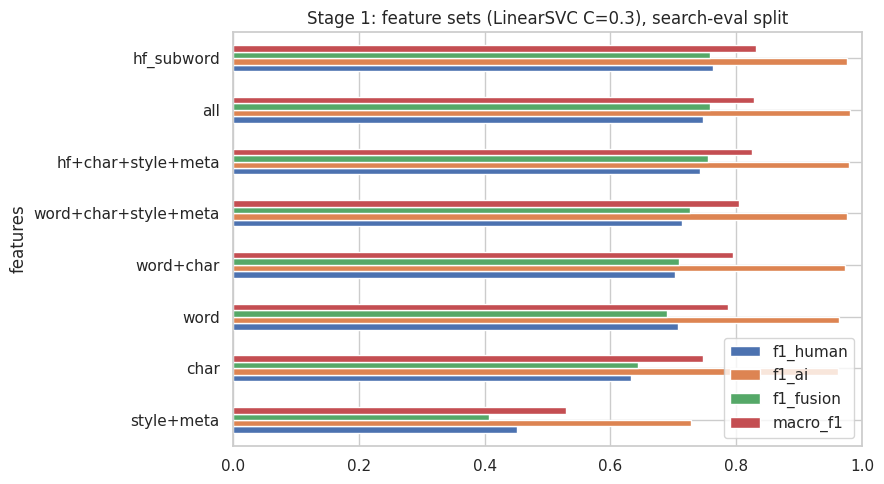

In [9]:
FEATURE_SETS = {
    "word":                 ["word"],
    "char":                 ["char"],
    "hf_subword":           ["hf"],
    "style+meta":           ["style", "meta"],
    "word+char":            ["word", "char"],
    "word+char+style+meta": ["word", "char", "style", "meta"],
    "hf+char+style+meta":   ["hf", "char", "style", "meta"],
    "all":                  ["word", "char", "hf", "style", "meta"],
}
FEATURE_SETS = {k: v for k, v in FEATURE_SETS.items() if all(b in AVAILABLE_BLOCKS for b in v)}

stage1 = []
for name, blocks in FEATURE_SETS.items():
    r = evaluate(LinearSVC(C=0.3), blocks)
    stage1.append({"features": name, **r})
    print(f"  {name:<24} macro-F1={r['macro_f1']:.4f}  ({r['fit_s']:.0f}s)")
stage1 = pd.DataFrame(stage1).sort_values("macro_f1", ascending=False).reset_index(drop=True)
display(stage1.style.background_gradient(subset=["macro_f1", "f1_human", "f1_ai", "f1_fusion"], cmap="Greens").format(precision=4))

ax = stage1.set_index("features")[["f1_human", "f1_ai", "f1_fusion", "macro_f1"]].iloc[::-1].plot.barh(figsize=(9, 5))
ax.set_title("Stage 1: feature sets (LinearSVC C=0.3), search-eval split"); ax.set_xlim(0, 1)
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

### Stage 2: model × regularisation on the 2 best feature sets

  hf_subword               LogReg C=4           macro-F1=0.8548  (183s)
  hf_subword               LogReg C=16          macro-F1=0.8594  (168s)
  hf_subword               LinearSVC C=0.1      macro-F1=0.8117  (10s)
  hf_subword               LinearSVC C=0.5      macro-F1=0.8358  (13s)
  hf_subword               SGD-huber a=1e-5     macro-F1=0.8381  (7s)
  hf_subword               SGD-huber a=3e-6     macro-F1=0.8330  (9s)
  hf_subword               ComplementNB a=0.03  macro-F1=0.6694  (1s)
  hf_subword               ComplementNB a=0.3   macro-F1=0.6158  (1s)
  all                      LogReg C=4           macro-F1=0.8389  (1260s)
  all                      LogReg C=16          macro-F1=0.8435  (1249s)
  all                      LinearSVC C=0.1      macro-F1=0.8231  (77s)
  all                      LinearSVC C=0.5      macro-F1=0.8288  (195s)
  all                      SGD-huber a=1e-5     macro-F1=0.8283  (74s)
  all                      SGD-huber a=3e-6     macro-F1=0.8351  (80s)
  a

,features,model,macro_f1,accuracy,f1_human,f1_ai,f1_fusion,fit_s
0,hf_subword,LogReg C=16,0.8594,0.8817,0.7903,0.9836,0.8043,168.4476
1,hf_subword,LogReg C=4,0.8548,0.8777,0.7832,0.9823,0.7988,182.9674
2,all,LogReg C=16,0.8435,0.8681,0.7661,0.9801,0.7843,1248.6853
3,all,LogReg C=4,0.8389,0.8643,0.7601,0.9793,0.7773,1259.7981
4,hf_subword,SGD-huber a=1e-5,0.8381,0.8639,0.7615,0.9799,0.7729,6.8214
5,hf_subword,LinearSVC C=0.5,0.8358,0.8620,0.7618,0.9796,0.7661,12.9426
6,all,SGD-huber a=3e-6,0.8351,0.8621,0.7428,0.9822,0.7802,80.3275
7,hf_subword,SGD-huber a=3e-6,0.8330,0.8593,0.7581,0.9794,0.7615,8.8632
8,all,LinearSVC C=0.5,0.8288,0.8563,0.7468,0.9814,0.7582,194.7538
9,all,SGD-huber a=1e-5,0.8283,0.8559,0.7391,0.9850,0.7608,73.5436


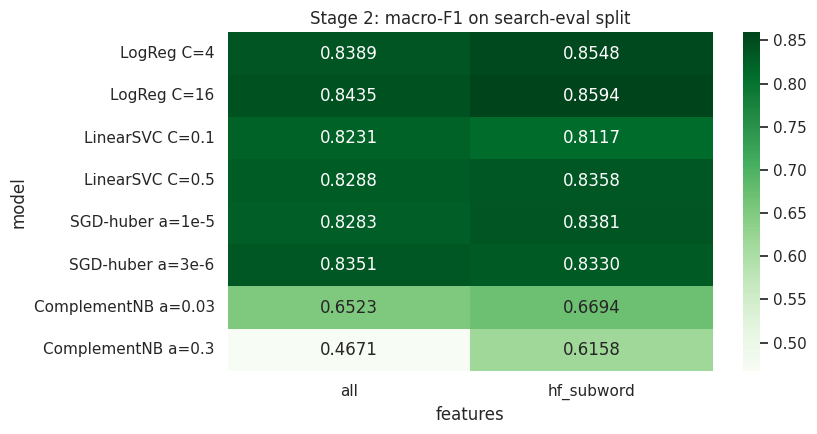

best: features=hf_subword ['hf'] | model=LogReg C=16 | macro-F1=0.8594


In [10]:
MODEL_GRID = {
    "LogReg C=4":           LogisticRegression(C=4, max_iter=1000),
    "LogReg C=16":          LogisticRegression(C=16, max_iter=1000),
    "LinearSVC C=0.1":      LinearSVC(C=0.1),
    "LinearSVC C=0.5":      LinearSVC(C=0.5),
    "SGD-huber a=1e-5":     SGDClassifier(loss="modified_huber", alpha=1e-5, max_iter=50, tol=1e-4, random_state=RANDOM_STATE),
    "SGD-huber a=3e-6":     SGDClassifier(loss="modified_huber", alpha=3e-6, max_iter=50, tol=1e-4, random_state=RANDOM_STATE),
    "ComplementNB a=0.03":  ComplementNB(alpha=0.03),
    "ComplementNB a=0.3":   ComplementNB(alpha=0.3),
}
top_sets = stage1["features"].head(2).tolist()

stage2 = []
for fs in top_sets:
    for mname, model in MODEL_GRID.items():
        r = evaluate(model, FEATURE_SETS[fs])
        stage2.append({"features": fs, "model": mname, **r})
        print(f"  {fs:<24} {mname:<20} macro-F1={r['macro_f1']:.4f}  ({r['fit_s']:.0f}s)")
stage2 = pd.DataFrame(stage2).sort_values("macro_f1", ascending=False).reset_index(drop=True)
display(stage2.style.background_gradient(subset=["macro_f1", "f1_human", "f1_ai", "f1_fusion"], cmap="Greens").format(precision=4))

piv = stage2.pivot(index="model", columns="features", values="macro_f1").loc[list(MODEL_GRID)]
plt.figure(figsize=(1.8 * len(top_sets) + 5, 4.5))
sns.heatmap(piv, annot=True, fmt=".4f", cmap="Greens"); plt.title("Stage 2: macro-F1 on search-eval split")
plt.tight_layout(); plt.show()

BEST = stage2.iloc[0]
BEST_BLOCKS, BEST_MODEL = FEATURE_SETS[BEST["features"]], MODEL_GRID[BEST["model"]]
print(f"best: features={BEST['features']} {BEST_BLOCKS} | model={BEST['model']} | macro-F1={BEST['macro_f1']:.4f}")

### What do the handcrafted features say? (LogReg on `style` only, coefficients)
Hashing hides n-gram names, but the handcrafted block is readable. The plot shows each feature's coefficient per class (one-vs-rest), on standardized inputs.

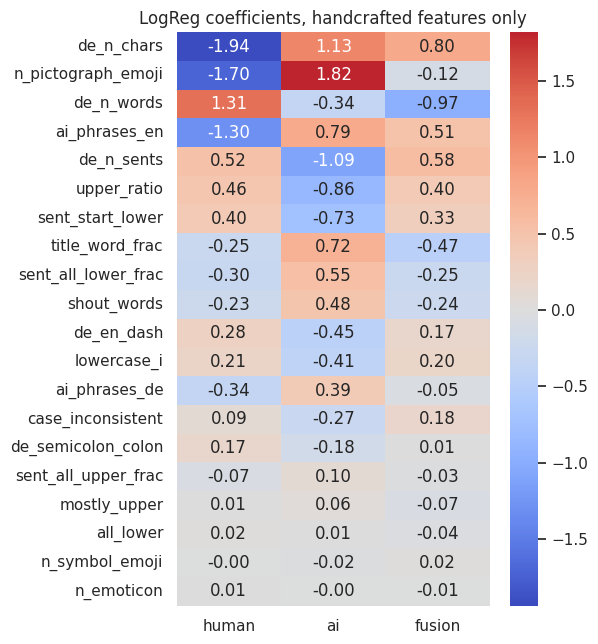

9589

In [11]:
from sklearn.preprocessing import StandardScaler
Xs = StandardScaler().fit_transform(style_search.loc[s_tr.index].values)
lr_style = LogisticRegression(C=1.0, max_iter=2000).fit(Xs, y_str)
coef = pd.DataFrame(lr_style.coef_.T, index=STYLE_COLS, columns=lr_style.classes_)[CLASSES]
coef = coef.loc[coef.abs().max(axis=1).sort_values(ascending=False).index]
plt.figure(figsize=(6, 0.28 * len(coef) + 1))
sns.heatmap(coef, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("LogReg coefficients, handcrafted features only"); plt.tight_layout(); plt.show()

del blk_tr, blk_va, blk_state; gc.collect()

## Final model: fit on the big train pool, evaluate on the held-out validation set

In [12]:
final_state, Xtr_parts = {}, []
for kind in BEST_BLOCKS:
    with timer(f"final block '{kind}' on {len(final_tr):,} rows"):
        final_state[kind], X = fit_block(kind, final_tr)
        Xtr_parts.append(X)
X_final = sp.hstack(Xtr_parts, format="csr"); del Xtr_parts; gc.collect()
print(f"X_final {X_final.shape}, nnz={X_final.nnz:,} (~{(X_final.data.nbytes + X_final.indices.nbytes) / 1e9:.1f} GB)")

with timer(f"fit {BEST['model']}"):
    final_model = clone(BEST_MODEL).fit(X_final, final_tr[LABEL].values)
del X_final; gc.collect()

def featurize(df):
    return sp.hstack([transform_block(k, final_state[k], df) for k in BEST_BLOCKS], format="csr")

with timer("predict validation"):
    val_pred = final_model.predict(featurize(val))
y_val = val[LABEL].values

[start] final block 'hf' on 150,000 rows ...
[done]  final block 'hf' on 150,000 rows: 305.1s
X_final (150000, 1048576), nnz=142,538,676 (~1.1 GB)
[start] fit LogReg C=16 ...
[done]  fit LogReg C=16: 1487.8s
[start] predict validation ...
[done]  predict validation: 51.2s


### Per-class metrics

Validation (20,000 rows) | macro-F1 = 0.8832 | accuracy = 0.9023
(majority-class baseline 'ai': macro-F1 = 0.2062)

              precision    recall  f1-score   support

       human     0.8022    0.8343    0.8179      4900
          ai     0.9880    0.9926    0.9903      8954
      fusion     0.8583    0.8251    0.8414      6146

    accuracy                         0.9023     20000
   macro avg     0.8828    0.8840    0.8832     20000
weighted avg     0.9026    0.9023    0.9023     20000



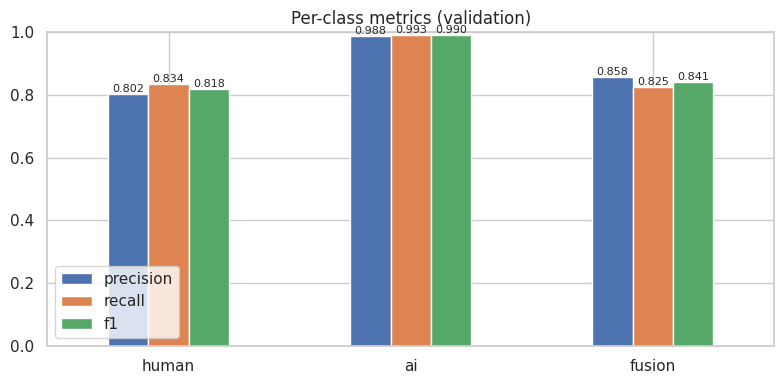

In [13]:
VAL_MACRO_F1 = f1_score(y_val, val_pred, average="macro")
print(f"Validation ({len(val):,} rows) | macro-F1 = {VAL_MACRO_F1:.4f} | "
      f"accuracy = {accuracy_score(y_val, val_pred):.4f}")
majority = pd.Series(final_tr[LABEL]).mode()[0]
print(f"(majority-class baseline '{majority}': macro-F1 = "
      f"{f1_score(y_val, np.full(len(y_val), majority), average='macro'):.4f})\n")
print(classification_report(y_val, val_pred, labels=CLASSES, digits=4))

p, r, f, s = precision_recall_fscore_support(y_val, val_pred, labels=CLASSES)
per_class = pd.DataFrame({"precision": p, "recall": r, "f1": f, "support": s}, index=CLASSES)
ax = per_class[["precision", "recall", "f1"]].plot.bar(rot=0, figsize=(8, 4), ylim=(0, 1), title="Per-class metrics (validation)")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8)
plt.tight_layout(); plt.show()

### Confusion matrix

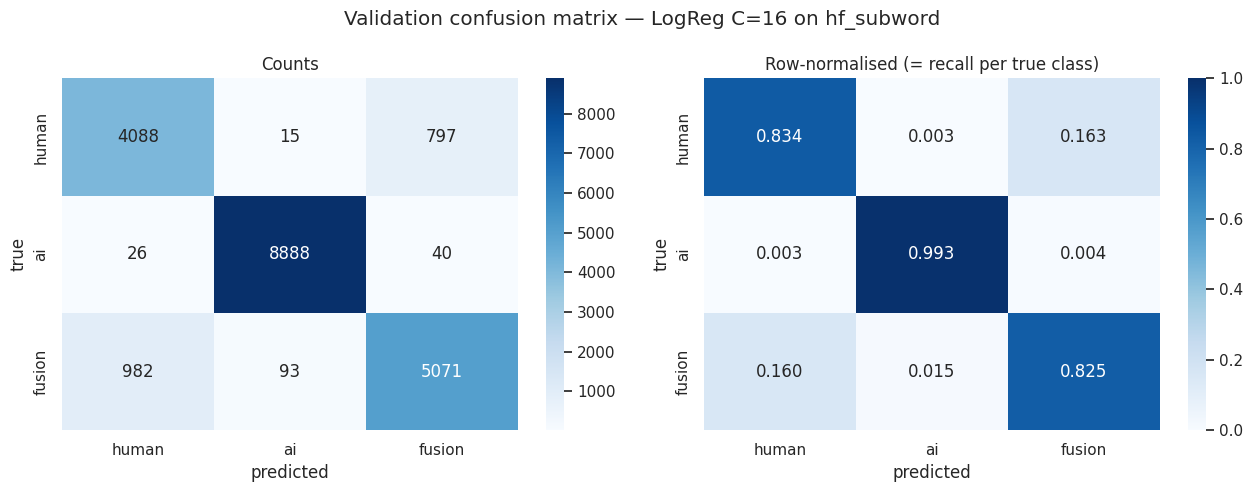

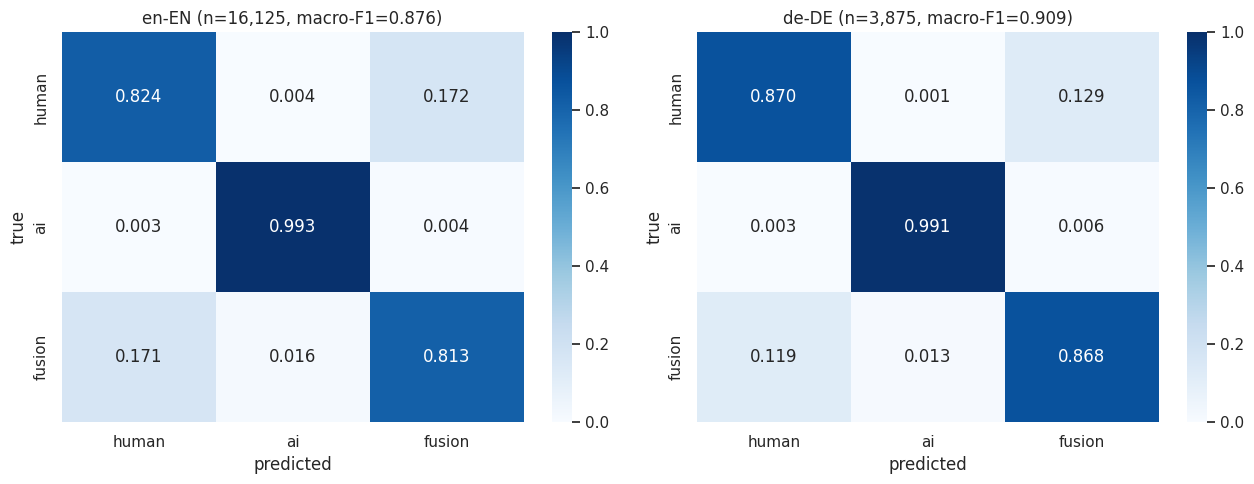

In [14]:
cm = confusion_matrix(y_val, val_pred, labels=CLASSES)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0])
axes[0].set_title("Counts"); axes[0].set_xlabel("predicted"); axes[0].set_ylabel("true")
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1,
            xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1])
axes[1].set_title("Row-normalised (= recall per true class)"); axes[1].set_xlabel("predicted"); axes[1].set_ylabel("true")
plt.suptitle(f"Validation confusion matrix — {BEST['model']} on {BEST['features']}"); plt.tight_layout(); plt.show()

# per language
fig, axes = plt.subplots(1, len(LANGS), figsize=(6.5 * len(LANGS), 5))
for ax, lang in zip(np.atleast_1d(axes), LANGS):
    m = (val[LANG] == lang).values
    c = confusion_matrix(y_val[m], val_pred[m], labels=CLASSES)
    sns.heatmap(c / c.sum(axis=1, keepdims=True), annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set_title(f"{lang} (n={m.sum():,}, macro-F1={f1_score(y_val[m], val_pred[m], average='macro'):.3f})")
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()

### Where does it fail? Scores per language × domain

In [15]:
rows = []
for (lang, dom), g in val.assign(pred=val_pred).groupby([LANG, DOMAIN]):
    f1s = f1_score(g[LABEL], g["pred"], labels=CLASSES, average=None, zero_division=0)
    rows.append({"lang": lang, "domain": dom, "n": len(g),
                 "macro_f1": f1_score(g[LABEL], g["pred"], average="macro", zero_division=0),
                 "accuracy": accuracy_score(g[LABEL], g["pred"]), **{f"f1_{c}": v for c, v in zip(CLASSES, f1s)}})
by_dom = pd.DataFrame(rows).sort_values("macro_f1")
display(by_dom.style.background_gradient(subset=["macro_f1", "f1_human", "f1_ai", "f1_fusion"], cmap="RdYlGn", vmin=0.4, vmax=1)
        .format(precision=3))

,lang,domain,n,macro_f1,accuracy,f1_human,f1_ai,f1_fusion
6,en-EN,gutenberg,508,0.689,0.959,0.529,0.994,0.545
3,en-EN,blog_authorship_corpus,2977,0.746,0.765,0.651,0.966,0.619
1,de-DE,gutenberg,31,0.816,0.935,0.800,0.980,0.667
2,en-EN,arxiv_papers,1050,0.871,0.981,0.688,1.000,0.925
8,en-EN,student_essays,3973,0.906,0.918,0.837,0.992,0.889
7,en-EN,house_of_commons,2340,0.906,0.926,0.848,0.994,0.877
0,de-DE,bundestag,3844,0.910,0.916,0.861,0.990,0.878
5,en-EN,euro_court_cases,2025,0.912,0.924,0.844,0.996,0.897
4,en-EN,cnn_news,3252,0.913,0.927,0.889,0.996,0.854


### Error examples

In [16]:
err = val.assign(pred=val_pred)
err = err[err[LABEL] != err["pred"]]
print("most common confusions:"); display(err.groupby([LABEL, "pred"]).size().sort_values(ascending=False).rename("n").to_frame())
for (t, pr), g in err.groupby([LABEL, "pred"]):
    print(f"\n--- true={t} → pred={pr} ({len(g)})")
    for _, row in g.sample(min(2, len(g)), random_state=RANDOM_STATE).iterrows():
        print(f"   [{row[LANG]}|{row[DOMAIN]}]", repr(row[TEXT][:220]))

most common confusions:


n
label  pred       
fusion human   982
human  fusion  797
fusion ai       93
ai     fusion   40
       human    26
human  ai       15


--- true=ai → pred=fusion (40)
   [en-EN|blog_authorship_corpus] "Well, tis true I tell thee! Went to this land where I made the animals dance. urlLink The whole lot of 'em!"
   [en-EN|cnn_news] "M'Baye Niang looks set to be shipped off AC Milan this summer, with West Ham United reportedly close to snapping him up on loan. The young forward has been in trouble at the San Siro, falling out of favor with manager Vi"

--- true=ai → pred=human (26)
   [en-EN|house_of_commons] 'I have the honour to inform the House that Royal Assent has been given to the Consolidated Fund Act 2009. This Act is now law.'
   [en-EN|blog_authorship_corpus] "Just got back from Wonderland! It was so much fun. I'm beat, but I'll try to work on the blog later."

--- true=fusion → pred=ai (93)
   [en-EN|blog_authorship_corpus] ', providing essential tools for knowledge management success. Chapters include: Health services: a contemporary approach Health service users of information Health service libraries Health 

## Predict test & save submission
Saved to `/kaggle/working/submission.csv` (the notebook output on Kaggle), or to the current folder when run locally. Format: `id,label`, one row per test id, in `sample_submission.csv` order.

In [17]:
with timer("predict test"):
    test_pred = final_model.predict(featurize(test))

sub = sample_sub[["id"]].merge(pd.DataFrame({"id": test["id"].values, "label": test_pred}), on="id", how="left")
assert sub["label"].notna().all() and len(sub) == len(sample_sub) and set(sub["label"]) <= set(CLASSES)

OUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
SUB_PATH = OUT_DIR / "submission.csv"
sub.to_csv(SUB_PATH, index=False)
print(f"saved {SUB_PATH.resolve()} {sub.shape}")
display(sub.head())
display(pd.concat({"train share": train[LABEL].value_counts(normalize=True),
                   "test pred share": sub["label"].value_counts(normalize=True)}, axis=1).loc[CLASSES].round(3))

[start] predict test ...
[done]  predict test: 55.5s
saved /kaggle/working/submission.csv (25000, 2)


,id,label
0,8ff2d1,ai
1,a261cf,human
2,ad5614,fusion
3,3a23ac,ai
4,28b4e5,ai


,train share,test pred share
label,,
human,0.245,0.272
ai,0.448,0.518
fusion,0.307,0.210


## Submit to the competition
Runs only when `SUBMIT = True` and credentials are found. The notebook looks for them in this order:
- Kaggle notebook secrets `KAGGLE_USERNAME` + `KAGGLE_KEY`, or `KAGGLE_API_TOKEN`;
- the same names as environment variables, or in a local `.env` file;
- `~/.kaggle/kaggle.json`.

Without credentials it prints how to submit manually. The CSV is saved either way.

In [18]:
def load_kaggle_credentials():
    names = ["KAGGLE_USERNAME", "KAGGLE_KEY", "KAGGLE_API_TOKEN"]
    try:                                               # Kaggle notebook secrets (Add-ons -> Secrets)
        from kaggle_secrets import UserSecretsClient
        client = UserSecretsClient()
        for n in names:
            if not os.environ.get(n):
                try:
                    os.environ[n] = client.get_secret(n)
                except Exception:
                    pass
    except ImportError:
        pass
    env_file = Path(".env")                            # local runs: KEY=VALUE lines
    if env_file.exists():
        for line in env_file.read_text().splitlines():
            k, _, v = line.partition("=")
            if k.strip() in names and v.strip() and not os.environ.get(k.strip()):
                os.environ[k.strip()] = v.strip().strip("'\"")
    return bool((os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY"))
                or os.environ.get("KAGGLE_API_TOKEN")
                or (Path.home() / ".kaggle" / "kaggle.json").exists())

def kaggle_cli(*args):
    r = subprocess.run(["kaggle", *args], capture_output=True, text=True)
    print((r.stdout + r.stderr).strip())
    return r.returncode == 0

if not SUBMIT:
    print(f"SUBMIT=False: {SUB_PATH} saved, not submitted.")
elif not load_kaggle_credentials():
    print("No Kaggle API credentials found, so not submitted.\n"
          "Add the notebook secrets KAGGLE_USERNAME + KAGGLE_KEY (or KAGGLE_API_TOKEN) and re-run this cell,\n"
          "or submit manually: Save Version -> open the version -> Output -> Submit.")
else:
    # recent CLI version: supports KAGGLE_API_TOKEN; needs internet
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "kaggle"], check=False)
    if shutil.which("kaggle") is None:
        print("kaggle CLI not found after install (no internet?). Submit manually: Output -> Submit.")
    else:
        msg = f"TF-IDF {BEST['features']} + {BEST['model']} | val macro-F1 {VAL_MACRO_F1:.4f}"
        if kaggle_cli("competitions", "submit", "-c", COMP, "-f", str(SUB_PATH), "-m", msg):
            print("\nsubmitted. Latest submissions:")
            kaggle_cli("competitions", "submissions", "-c", COMP)
        else:
            print("submission failed. Check that you accepted the competition rules and that the credentials are valid.")

SUBMIT=False: /kaggle/working/submission.csv saved, not submitted.


## Summary
- **Search**: stage 1 compares the vectorizers (word / char / HF-subword TF-IDF, handcrafted AI-phrase + emoji + capitalization + German-only features, and their combinations). Stage 2 tunes the model and its regularisation on the 2 best feature sets. Tables and heatmaps are above.
- **Final**: the best combination is refit on `FINAL_N` rows. The validation section reports per-class precision/recall/F1 and confusion matrices on 20k untouched validation rows.
- **Output**: `submission.csv` in the Kaggle working directory, submitted automatically when credentials are set.
- To trade time and RAM for accuracy, set `FINAL_N=None` (all rows) or raise `CHAR_MAX_CHARS`.